### 1. Import Library

In [1]:
import time
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

### 2. Import Data และแบ่ง Train / Test (80 / 20)
- ใช้ชุดข้อมูล Iris : 150 ตัวอย่าง, 4 features, 3 สายพันธุ์ (คลาสละ 50)
- `stratify=y` ทำให้ชุด Train และ Test มีสัดส่วนแต่ละสายพันธุ์เท่ากัน
- KNN วัด **ระยะทาง** จึงต้องปรับสเกลข้อมูล (StandardScaler) โดย fit จากชุด Train เท่านั้น

In [16]:
iris = load_iris()
X, y = iris.data, iris.target
class_names = iris.target_names

df = pd.DataFrame(X, columns=iris.feature_names)
df["species"] = class_names[y]
print("ขนาดข้อมูล:", X.shape)
print("จำนวนแต่ละคลาส:", np.bincount(y))
df.head()

ขนาดข้อมูล: (150, 4)
จำนวนแต่ละคลาส: [50 50 50]


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [20]:
# แบ่ง Train 80% / Test 20%
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# ปรับสเกล: fit กับ Train แล้วใช้ค่าเดียวกันแปลง Test (กันข้อมูล Test รั่วเข้าไปตอนเทรน)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (120, 4)  Test: (30, 4)


### 3. ฟังก์ชันช่วยวัดผล
ใช้ฟังก์ชันเดียวกันวัดทุกโมเดล เพื่อให้เปรียบเทียบได้ยุติธรรม : จับเวลาเทรน, เวลาทำนาย และ accuracy ทั้ง Train / Test

In [4]:
def evaluate(name, model):
    # เทรน + จับเวลา
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    train_time = time.perf_counter() - t0

    # ทำนายชุด Test + จับเวลา
    t0 = time.perf_counter()
    y_pred = model.predict(X_test)
    test_time = time.perf_counter() - t0

    result = {
        "Model": name,
        "Train Acc": accuracy_score(y_train, model.predict(X_train)),
        "Test Acc": accuracy_score(y_test, y_pred),
        "Train Time (s)": train_time,
        "Test Time (s)": test_time,
    }
    print(f"{name}: Train Acc = {result['Train Acc']:.4f} | Test Acc = {result['Test Acc']:.4f} "
          f"| Train {train_time:.4f}s | Test {test_time:.4f}s")
    return result, y_pred

### 4. โมเดลเดี่ยว (Baseline) : KNN
KNN ทายคลาสของจุดใหม่โดยดู **เพื่อนบ้านที่ใกล้ที่สุด k ตัว** แล้วตอบตามเสียงข้างมาก (ใช้ k = 5)

In [5]:
K = 5
knn_result, knn_pred = evaluate("KNN (single)", KNeighborsClassifier(n_neighbors=K))

KNN (single): Train Acc = 0.9750 | Test Acc = 0.9333 | Train 0.0012s | Test 0.0037s


### 5. Bagging (เขียนเอง + Parallel Computing)
เปรียบเหมือน **ถามหลายคนแล้วเอาเสียงข้างมาก**
1. **Bootstrap** : สุ่มข้อมูลจาก Train แบบใส่คืน ให้ได้ชุดใหม่ขนาดเท่าเดิม (บางตัวซ้ำ บางตัวไม่ถูกเลือก)
2. **เทรนหลายโมเดลพร้อมกัน** : แต่ละชุดสุ่มได้ KNN 1 ตัว ใช้ `ThreadPoolExecutor` (Python built-in) ให้เทรนแบบขนาน
3. **Majority Vote** : ทุกโมเดลทาย แล้วเลือกคำตอบที่ได้โหวตมากที่สุด

In [6]:
def majority_vote(all_preds, n_classes):
    # all_preds: (จำนวนโมเดล, จำนวนตัวอย่าง) → นับโหวตของแต่ละคลาส แล้วเลือกคลาสที่ได้โหวตมากสุด
    votes = np.zeros((all_preds.shape[1], n_classes))
    for preds in all_preds:
        votes[np.arange(len(preds)), preds] += 1
    return votes.argmax(axis=1)


class MyBagging:
    def __init__(self, n_estimators=50, k=5, n_workers=4, seed=42):
        self.n_estimators = n_estimators
        self.k = k
        self.n_workers = n_workers
        self.seed = seed

    def _train_one(self, model_index):
        # สุ่ม bootstrap (seed ต่างกันในแต่ละโมเดล) แล้วเทรน KNN 1 ตัว
        rng = np.random.default_rng(self.seed + model_index)
        idx = rng.integers(0, len(self.X_), len(self.X_))
        return KNeighborsClassifier(n_neighbors=self.k).fit(self.X_[idx], self.y_[idx])

    def fit(self, X, y):
        self.X_, self.y_ = X, y
        self.n_classes_ = len(np.unique(y))
        # Parallel: ส่งงานเทรนทุกโมเดลเข้า thread pool พร้อมกัน
        with ThreadPoolExecutor(max_workers=self.n_workers) as pool:
            self.models_ = list(pool.map(self._train_one, range(self.n_estimators)))
        return self

    def predict(self, X):
        # ให้ทุกโมเดลทายแบบขนาน แล้วโหวต
        with ThreadPoolExecutor(max_workers=self.n_workers) as pool:
            all_preds = np.array(list(pool.map(lambda m: m.predict(X), self.models_)))
        return majority_vote(all_preds, self.n_classes_)

In [7]:
bagging_result, bagging_pred = evaluate("Bagging (KNN x50)", MyBagging(n_estimators=50, k=K))

Bagging (KNN x50): Train Acc = 0.9750 | Test Acc = 0.9333 | Train 0.0449s | Test 0.0583s


### 6. Boosting (AdaBoost เขียนเอง)
เปรียบเหมือน **ให้นักเรียนรุ่นถัดไปตั้งใจแก้ข้อที่รุ่นก่อนทำผิด**
1. เริ่มต้นให้ข้อมูลทุกตัวมี **น้ำหนักเท่ากัน**
2. แต่ละรอบ สุ่มข้อมูลตามน้ำหนัก (ตัวที่น้ำหนักมากถูกเลือกบ่อย) แล้วเทรน KNN
   > KNN ไม่รองรับ `sample_weight` จึงใช้วิธี **สุ่มตามน้ำหนัก** แทน
3. คำนวณ error ถ่วงน้ำหนัก → ได้ค่า **alpha** (โมเดลที่ทายแม่นจะมีเสียงโหวตมาก)
4. เพิ่มน้ำหนักให้ตัวที่ทายผิด เพื่อให้รอบถัดไปสนใจมันมากขึ้น
5. ตอนทำนาย ใช้ **โหวตถ่วงน้ำหนักด้วย alpha** (สูตร SAMME สำหรับหลายคลาส)

In [17]:
class MyAdaBoost:
    def __init__(self, n_estimators=50, k=5, seed=42):
        self.n_estimators = n_estimators
        self.k = k
        self.seed = seed

    def fit(self, X, y):
        n = len(X)
        K = len(np.unique(y))
        rng = np.random.default_rng(self.seed)
        w = np.full(n, 1 / n)                      # 1) น้ำหนักเริ่มต้นเท่ากัน
        self.models_, self.alphas_, self.n_classes_ = [], [], K

        for _ in range(self.n_estimators):
            idx = rng.choice(n, n, p=w)            # 2) สุ่มข้อมูลตามน้ำหนัก
            model = KNeighborsClassifier(n_neighbors=self.k).fit(X[idx], y[idx])

            wrong = model.predict(X) != y
            err = w[wrong].sum()                   # 3) error ถ่วงน้ำหนัก
            if err >= 1 - 1 / K:                   # แย่กว่าการเดาสุ่ม → ข้ามรอบนี้
                continue
            err = max(err, 1e-10)                  # กันหารด้วย 0 ตอนทายถูกหมด
            alpha = np.log((1 - err) / err) + np.log(K - 1)

            self.models_.append(model)
            self.alphas_.append(alpha)

            w = w * np.exp(alpha * wrong)          # 4) เพิ่มน้ำหนักตัวที่ทายผิด
            w = w / w.sum()
        return self

    def predict(self, X):
        # 5) โหวตถ่วงน้ำหนักด้วย alpha
        scores = np.zeros((len(X), self.n_classes_))
        for model, alpha in zip(self.models_, self.alphas_):
            scores[np.arange(len(X)), model.predict(X)] += alpha
        return scores.argmax(axis=1)

In [18]:
boost_model = MyAdaBoost(n_estimators=50, k=K)
boosting_result, boosting_pred = evaluate("Boosting (KNN x50)", boost_model)
print("จำนวนโมเดลที่ถูกใช้จริง:", len(boost_model.models_))

Boosting (KNN x50): Train Acc = 1.0000 | Test Acc = 0.9667 | Train 0.0841s | Test 0.0459s
จำนวนโมเดลที่ถูกใช้จริง: 50


### 7. เปรียบเทียบผลลัพธ์ทั้ง 3 แบบ

In [10]:
results = pd.DataFrame([knn_result, bagging_result, boosting_result]).set_index("Model")
results.style.format({"Train Acc": "{:.2%}", "Test Acc": "{:.2%}",
                      "Train Time (s)": "{:.4f}", "Test Time (s)": "{:.4f}"})

,Train Acc,Test Acc,Train Time (s),Test Time (s)
Model,,,,
KNN (single),97.50%,93.33%,0.0012,0.0037
Bagging (KNN x50),97.50%,93.33%,0.0449,0.0583
Boosting (KNN x50),100.00%,96.67%,0.0837,0.0447


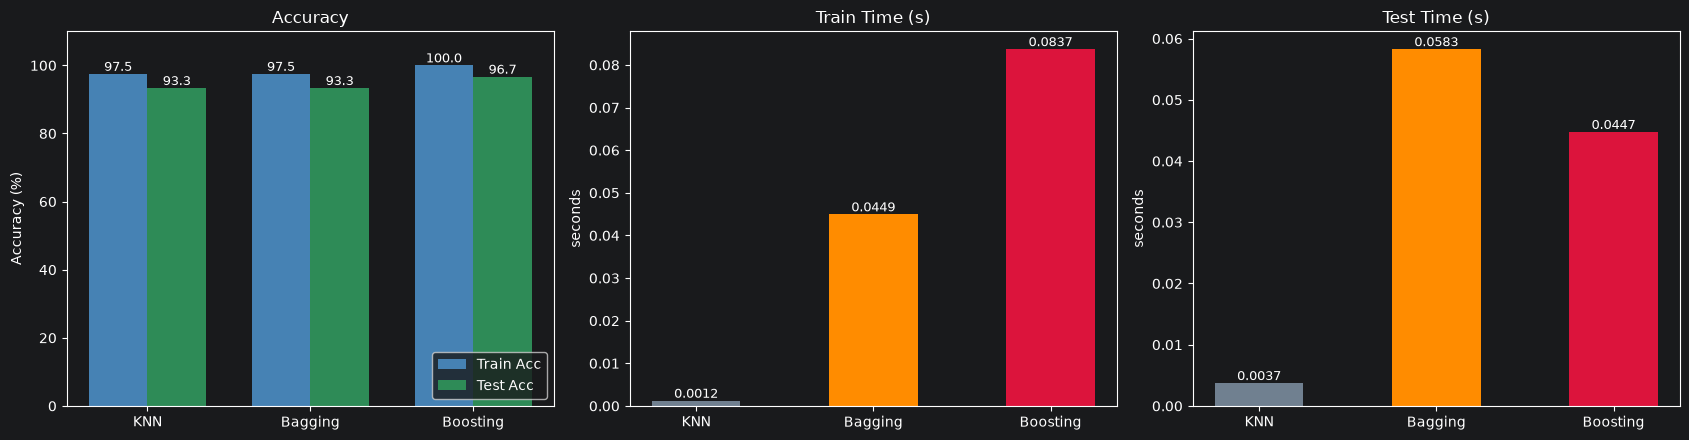

In [11]:
names = ["KNN", "Bagging", "Boosting"]
colors = ["slategray", "darkorange", "crimson"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# กราฟ 1: Accuracy Train vs Test
x = np.arange(3)
for offset, col, c in [(-0.18, "Train Acc", "steelblue"), (0.18, "Test Acc", "seagreen")]:
    bars = axes[0].bar(x + offset, results[col] * 100, width=0.36, color=c, label=col)
    axes[0].bar_label(bars, fmt="%.1f", fontsize=9)
axes[0].set_xticks(x, names)
axes[0].set_ylim(0, 110)
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_title("Accuracy")
axes[0].legend(loc="lower right")

# กราฟ 2-3: เวลาเทรน / เวลาทำนาย
for ax, col in [(axes[1], "Train Time (s)"), (axes[2], "Test Time (s)")]:
    bars = ax.bar(names, results[col], color=colors, width=0.5)
    ax.bar_label(bars, fmt="%.4f", fontsize=9)
    ax.set_title(col)
    ax.set_ylabel("seconds")

plt.tight_layout()
plt.show()

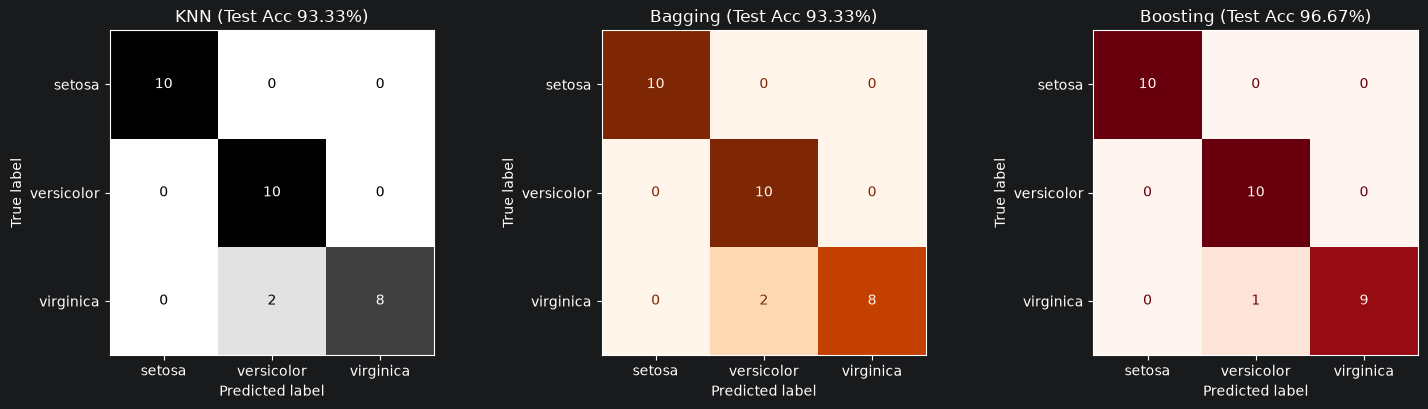

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.91      1.00      0.95        10
   virginica       1.00      0.90      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [12]:
# Confusion Matrix ของชุด Test ทั้ง 3 โมเดล
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, name, pred, cmap in zip(axes, names, [knn_pred, bagging_pred, boosting_pred],
                                ["Greys", "Oranges", "Reds"]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=class_names).plot(
        ax=ax, cmap=cmap, colorbar=False)
    ax.set_title(f"{name} (Test Acc {accuracy_score(y_test, pred):.2%})")
plt.tight_layout()
plt.show()

print(classification_report(y_test, boosting_pred, target_names=class_names))

### 8. ทดลองเพิ่ม : จำนวนโมเดลย่อยมีผลอย่างไร
Test set มีแค่ 30 ตัว (ทายผิด 1 ตัว = 3.33%) ผลรอบเดียวจึงแกว่งได้ง่าย
เลยเทรนซ้ำด้วย **seed ต่างกัน 10 รอบ** แล้วใช้ค่าเฉลี่ย (ยังแบ่ง 80/20 เหมือนเดิม)

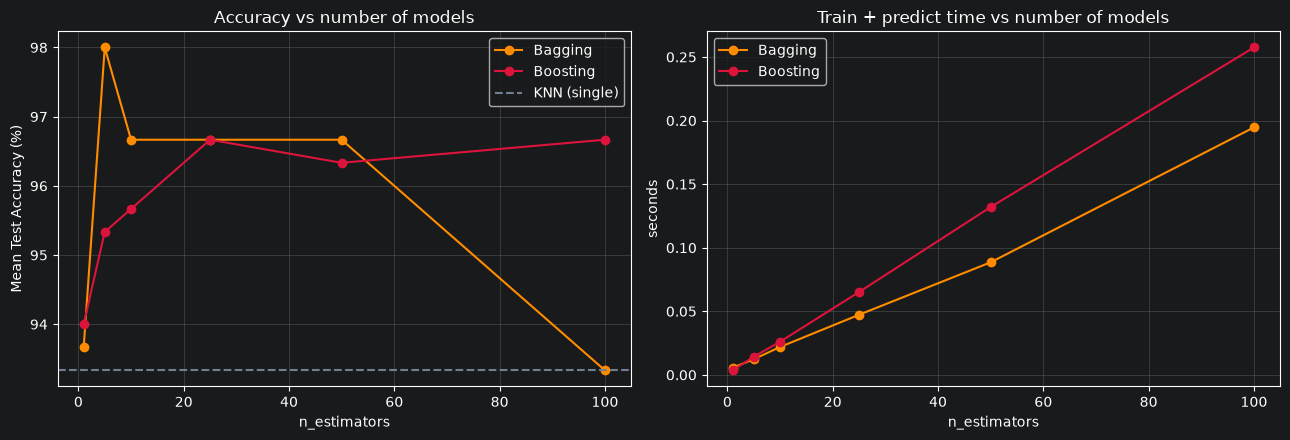

Method,Bagging,Boosting
n_estimators,,
1,93.67%,94.00%
5,98.00%,95.33%
10,96.67%,95.67%
25,96.67%,96.67%
50,96.67%,96.33%
100,93.33%,96.67%


In [13]:
n_list = [1, 5, 10, 25, 50, 100]
seeds = range(10)
rows = []
for n in n_list:
    for name, Model in [("Bagging", MyBagging), ("Boosting", MyAdaBoost)]:
        t0 = time.perf_counter()
        accs = [accuracy_score(y_test, Model(n_estimators=n, k=K, seed=s).fit(X_train, y_train).predict(X_test))
                for s in seeds]
        rows.append({"n_estimators": n, "Method": name, "Test Acc": np.mean(accs),
                     "Time per run (s)": (time.perf_counter() - t0) / len(seeds)})

exp = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, c in [("Bagging", "darkorange"), ("Boosting", "crimson")]:
    part = exp[exp.Method == name]
    axes[0].plot(part.n_estimators, part["Test Acc"] * 100, "o-", color=c, label=name)
    axes[1].plot(part.n_estimators, part["Time per run (s)"], "o-", color=c, label=name)
axes[0].axhline(knn_result["Test Acc"] * 100, ls="--", color="slategray", label="KNN (single)")
axes[0].set(xlabel="n_estimators", ylabel="Mean Test Accuracy (%)", title="Accuracy vs number of models")
axes[1].set(xlabel="n_estimators", ylabel="seconds", title="Train + predict time vs number of models")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

exp.pivot(index="n_estimators", columns="Method", values="Test Acc").style.format("{:.2%}")

### 9. สรุปผล
- **ความแม่นยำ** : Boosting ได้ Test Accuracy สูงสุด (96.67%) ส่วน KNN เดี่ยวกับ Bagging ได้เท่ากัน (93.33%)
  แต่ใน Test 30 ตัว ส่วนต่างนี้คือทายผิดต่างกันแค่ **1 ตัว** ผลจึงต่างกันไม่มาก
- **ทำไม Bagging ช่วยได้น้อย** : KNN เป็นโมเดลที่ **เสถียร** (variance ต่ำ) สุ่มข้อมูลใหม่แล้วผลแทบไม่เปลี่ยน
  การโหวตจากหลายโมเดลที่ทายเหมือนกันจึงไม่ช่วยมาก (Bagging เหมาะกับโมเดลที่ variance สูง เช่น Decision Tree ลึกๆ)
- **Boosting** ให้รอบหลังๆ โฟกัสจุดที่ทายผิด (ส่วนใหญ่อยู่ตรงรอยต่อ versicolor / virginica) จึงแก้จุดยากได้ดีกว่า
  แต่ Train Accuracy = 100% แปลว่าเริ่มจำข้อมูล Train ได้หมด ต้องระวัง overfitting
- **เวลา** : ทั้ง Bagging และ Boosting ช้ากว่าโมเดลเดี่ยวหลายสิบเท่า เพราะต้องเทรน/ทำนาย 50 โมเดล
  และเวลาเพิ่มขึ้นตามจำนวนโมเดลแบบเส้นตรง
- **Parallel** : Iris เล็กมาก (120 ตัว) ค่าใช้จ่ายในการจัดการ thread จึงใกล้เคียงกับงานจริง ความเร็วที่ได้จาก parallel จะเห็นชัดเมื่อข้อมูลใหญ่ขึ้น
- **จำนวนโมเดลย่อย** : accuracy ขึ้นเร็วในช่วง 1–25 โมเดล หลังจากนั้นแทบไม่ดีขึ้น แต่เวลายังเพิ่มต่อ
  ประมาณ 10–25 โมเดลจึงคุ้มที่สุดสำหรับข้อมูลชุดนี้